# Transmissão de Calor 1: Trabalho de Métodos Numéricos
**Estudo transiente do aquecimento de um motor elétrico**.

**Laura Grazziotin Poletto,    24102922**



*   Utilizado o método EXPLÍCITO (Euler progressivo).
*   Foi escolhido utilizar Google Colab porque permite rodar partes do código conforme interesse:

      **Como usar:** *Ambiente de execução → Executar tudo*.

      A última seção (convergência de malha e sensibilidade) é mais lenta e fica atrás de um interruptor (`RODAR_EXTRAS`) que pode ser colocado como False ou True.


**Convenções**:

`T[j, i]` com `j` = linha em y (0 = fundo) e `i` = coluna em x (0 = linha de simetria).

Domínio = metade da ranhura (5 mm × 30 mm).

## 1. Importar bibliotecas

In [14]:
import os
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({'font.size': 11, 'axes.grid': True, 'grid.alpha': .3})
os.makedirs('figs', exist_ok=True)

## 2. Main

In [15]:
# Parâmetros
W = 10e-3          # largura
a = W / 2          # semilargura
H = 30e-3          # profundidade
k = 0.8            # condutividade térmica
rho = 5000.0       # massa específica
cp = 550.0         # calor específico
hn = 400.0         # h eq núcleo (lateral e fundo)
Tn = 90.0          # temperatura do núcleo
he = 50.0          # h eq entreferro (cima)
Te = 90.0          # temperatura do ar do entreferro
Ti = 90.0          # temperatura inicial
e1 = 3.5e6         # geração em potência de pico
e2 = 5.0e5         # geração em potência contínua
t1 = 90.0          # duração da potência de pico
Tmax_isol = 155.0  # limite da classe F

alpha = k / (rho * cp)



# --------------------------------------------------------


def criar_malha(Delta):
    nx = int(round(a / Delta)) + 1
    ny = int(round(H / Delta)) + 1

    # arrays com as coordenadas x, y dos nós
    "função np.linspace(início, fim, quantidade)"
    x = np.linspace(0, a, nx)
    y = np.linspace(0, H, ny)

    dxv = np.full(nx, Delta)   # Cria um array com tamanho nx
    dxv[0] = Delta / 2
    dxv[-1] = Delta / 2

    dyv = np.full(ny, Delta)   # Cria um array com tamanho ny
    dyv[0] = Delta / 2
    dyv[-1] = Delta / 2

    "np.outer() faz produto de vetores"
    V = np.outer(dyv, dxv)        # (matriz) volumes
    C = rho * cp * V              # (matriz) capacidade térmica
    Hlat = hn * dyv               # (array) H lateral
    Hbot = hn * dxv               # (array) H bottom
    Htop = he * dxv               # (array) H top

    return nx, ny, x, y, V, C, Hlat, Hbot, Htop



# ----------------------------------------------------



def calcular_ctes(D, dt):
    Fo = alpha * dt / D**2       # Fourier
    Bn = hn * D / k              # Biot (núcleo)
    Be = he * D / k              # Biot (entreferro)
    return Fo, Bn, Be


# Calcula a temperatura de cada nó no próximo passo de tempo (i+1)
def dar_passo(T, e, dt, D):
    Fo, Bn, Be = calcular_ctes(D, dt)
    g = Fo * e * D**2 / k        # termo de geração
    Tp = np.empty_like(T)        # T_próximo (matriz)

    # Nó 1
    Tp[1:-1, 1:-1] = (Fo * (T[1:-1, 2:] + T[1:-1, :-2] + T[2:, 1:-1] + T[:-2, 1:-1]) + (1 - 4*Fo) * T[1:-1, 1:-1] + g)

    # Nó 2
    Tp[1:-1, 0] = (Fo * (2*T[1:-1, 1] + T[2:, 0] + T[:-2, 0]) + (1 - 4*Fo) * T[1:-1, 0] + g)

    # Nó 3
    Tp[1:-1, -1] = (Fo * (2*T[1:-1, -2] + T[2:, -1] + T[:-2, -1]) + (1 - 4*Fo - 2*Fo*Bn) * T[1:-1, -1] + 2*Fo*Bn*Tn + g)

    # Nó 4
    Tp[0, 1:-1] = (Fo * (T[0, 2:] + T[0, :-2] + 2*T[1, 1:-1]) + (1 - 4*Fo - 2*Fo*Bn) * T[0, 1:-1] + 2*Fo*Bn*Tn + g)

    # Nó 5
    Tp[-1, 1:-1] = (Fo * (T[-1, 2:] + T[-1, :-2] + 2*T[-2, 1:-1]) + (1 - 4*Fo - 2*Fo*Be) * T[-1, 1:-1] + 2*Fo*Be*Te + g)

    # Nó 6
    Tp[0, 0] = (2*Fo * (T[0, 1] + T[1, 0]) + (1 - 4*Fo - 2*Fo*Bn) * T[0, 0] + 2*Fo*Bn*Tn + g)

    # Nó 7
    Tp[0, -1] = (2*Fo * (T[0, -2] + T[1, -1]) + (1 - 4*Fo - 4*Fo*Bn) * T[0, -1] + 4*Fo*Bn*Tn + g)

    # Nó 8
    Tp[-1, 0] = (2*Fo * (T[-1, 1] + T[-2, 0]) + (1 - 4*Fo - 2*Fo*Be) * T[-1, 0] + 2*Fo*Be*Te + g)

    # Nó 9
    Tp[-1, -1] = (2*Fo * (T[-1, -2] + T[-2, -1]) + (1 - 4*Fo - 2*Fo*Be - 2*Fo*Bn) * T[-1, -1] + 2*Fo*Be*Te + 2*Fo*Bn*Tn + g)


    return Tp


# q = hA(T_inf-T)
def calor_fronteira(T, Hlat, Hbot, Htop):
    qlat = Hlat * (Tn - T[:, -1])
    qbot = Hbot * (Tn - T[0, :])
    qtop = Htop * (Te - T[-1, :])
    return qlat, qbot, qtop


def calcular_dt_critico(D):
    Bn = hn * D / k
    Be = he * D / k
    Fo_max = min(1/4, 1/(4 + 2*Bn), 1/(4 + 2*Be), 1/(4 + 4*Bn), 1/(4 + 2*Be + 2*Bn))
    return Fo_max * D**2 / alpha


def escolhe_dt(D, dt_desejado=None, fator=0.9):
    dtc = calcular_dt_critico(D)
    if dt_desejado is None:
        dt = fator * dtc
    else:
        dt = min(dt_desejado, fator * dtc)

    n1 = int(np.ceil(t1 / dt - 1e-9))
    return t1 / n1, dtc


# ---------------------------------------------------------


# Simulação explícita e buscas
def simula(D, nx, ny, x, y, V, C, Hlat, Hbot, Htop, dt, t_fim, snapshots=(), passo_gif=0):
    n1 = int(round(t1 / dt))
    N = int(np.ceil(t_fim / dt))
    T = np.full((ny, nx), Ti)

    iA, jA = 0, ny - 1                       # ponto A
    iB, jB = nx - 1, ny - 1                  # ponto B
    iC, jC = 0, int(round((H - 15e-3) / D))  # ponto C
    iD, jD = 0, 0                            # ponto D

    t = np.arange(N + 1) * dt
    hist_A = np.zeros(N + 1)
    hist_B = np.zeros(N + 1)
    hist_C = np.zeros(N + 1)
    hist_D = np.zeros(N + 1)
    hist_Tmax = np.zeros(N + 1)
    hist_xmax = np.zeros(N + 1)
    hist_ymax = np.zeros(N + 1)
    hist_Qger = np.zeros(N + 1)
    hist_Qnuc = np.zeros(N + 1)
    hist_Qent = np.zeros(N + 1)
    hist_dEdt = np.zeros(N + 1)

    snap_steps = [int(round(s / dt)) for s in snapshots]
    campos_lista = []
    gif_tempos = []
    gif_campos = []
    V2 = 2.0                  # simulamos só metade, então aqui multiplicamos por 2

    for n in range(N + 1):
        if n < n1:
            e = e1
        else:
            e = e2


        Tnovo = dar_passo(T, e, dt, D)
        qlat, qbot, qtop = calor_fronteira(T, Hlat, Hbot, Htop)
        dEdt = V2 * np.sum(C * (Tnovo - T)) / dt

        hist_A[n] = T[jA, iA]
        hist_B[n] = T[jB, iB]
        hist_C[n] = T[jC, iC]
        hist_D[n] = T[jD, iD]
        jm, im = np.unravel_index(np.argmax(T), T.shape)
        hist_Tmax[n] = T[jm, im]
        hist_xmax[n] = x[im]
        hist_ymax[n] = y[jm]
        hist_Qger[n] = V2 * e * V.sum()
        hist_Qnuc[n] = V2 * (-(qlat.sum() + qbot.sum()))
        hist_Qent[n] = V2 * (-qtop.sum())
        hist_dEdt[n] = dEdt

        if n in snap_steps:
            campos_lista.append(T.copy())
        if passo_gif and n % passo_gif == 0:
            gif_tempos.append(t[n])
            gif_campos.append(T.copy())
        T = Tnovo

    return (t, n1, T, hist_A, hist_B, hist_C, hist_D,
            hist_Tmax, hist_xmax, hist_ymax,
            hist_Qger, hist_Qnuc, hist_Qent, hist_dEdt,
            campos_lista, gif_tempos, gif_campos)


def pico_apos(D, nx, ny, dt, t1_teste, extra=400.0):
    n1 = int(round(t1_teste / dt))
    N = n1 + int(extra / dt)
    T = np.full((ny, nx), Ti)
    Tmax = Ti
    queda = 0
    for n in range(N):
        e = e1 if n < n1 else e2
        T = dar_passo(T, e, dt, D)
        Tm = T.max()
        if Tm > Tmax:
            Tmax = Tm
            queda = 0
        elif n > n1:
            queda += 1
            if queda > int(100 / dt):
                break
    return Tmax


def t1_maximo(D, nx, ny, dt, alvo=None):
    if alvo is None:
        alvo = Tmax_isol

    lo, hi = 0, int(round(t1 / dt))
    if pico_apos(D, nx, ny, dt, hi * dt) <= alvo:
        return None

    while hi - lo > 1:
        mid = (lo + hi) // 2
        if pico_apos(D, nx, ny, dt, mid * dt) <= alvo:
            lo = mid
        else:
            hi = mid

    return lo * dt, hi * dt


def permanente(D, nx, ny, e):
    N = ny * nx
    dt0 = 0.9 * calcular_dt_critico(D)

    def residuo(T_vec):
        T_mat = T_vec.reshape(ny, nx)
        return (dar_passo(T_mat, e, dt0, D) - T_mat).ravel()

    b = residuo(np.zeros(N))
    A = np.zeros((N, N))
    for idx in range(N):
        u = np.zeros(N)
        u[idx] = 1.0
        A[:, idx] = residuo(u) - b
    T_sol = np.linalg.solve(A, -b)
    return T_sol.reshape(ny, nx)

## 3. Cria a malha


In [16]:
DELTA = 0.5e-3
DT_DESEJADO = 0.1
T_FIM = 1500.0        # tempo total simulado

nx, ny, x, y, V, C, Hlat, Hbot, Htop = criar_malha(DELTA)
dt, dtc = escolhe_dt(DELTA, DT_DESEJADO)
print(f'Malha: {nx} x {ny} = {nx*ny} nós  |  dt crítico = {dtc:.4f} s  |  dt adotado = {dt:.4f} s')
print(f'tau = alpha*dt/Delta² = {alpha*dt/DELTA**2:.4f}   |  t1 = {t1} s = {int(round(t1/dt))} passos')

Malha: 11 x 61 = 671 nós  |  dt crítico = 0.1719 s  |  dt adotado = 0.1000 s
tau = alpha*dt/Delta² = 0.1164   |  t1 = 90.0 s = 900 passos


## 4. Simulação transiente

In [17]:
snaps = (0, 30, 60, 90, 100, 120, 150, 200, 300)
(t, n1, T_final, hist_A, hist_B, hist_C, hist_D,
 hist_Tmax, hist_xmax, hist_ymax,
 hist_Qger, hist_Qnuc, hist_Qent, hist_dEdt,
 campos_lista, gif_tempos, gif_campos) = simula(DELTA, nx, ny, x, y, V, C, Hlat, Hbot, Htop,
                                                dt, T_FIM, snapshots=snaps, passo_gif=int(round(3.0 / dt)))
print('Simulação concluída')

Simulação concluída


## 5. Resultado (a) — temperatura máxima e limite da classe F

In [18]:
i = int(np.argmax(hist_Tmax))
print(f'T máx = {hist_Tmax[i]:.2f} °C  em t = {t[i]:.1f} s,  x = {hist_xmax[i]*1e3:.2f} mm (0 = simetria),  y = {hist_ymax[i]*1e3:.2f} mm')
print('Limite de 155 °C respeitado?', 'SIM' if hist_Tmax[i] <= Tmax_isol else 'NÃO')
res = t1_maximo(DELTA, nx, ny, dt)
if res is not None:
    print(f't1,máx ≈ {res[0]:.1f} s  (com {res[1]:.1f} s o limite já é ultrapassado; resolução = dt)')

T máx = 162.66 °C  em t = 90.0 s,  x = 0.00 mm (0 = simetria),  y = 16.50 mm
Limite de 155 °C respeitado? NÃO
t1,máx ≈ 72.4 s  (com 72.5 s o limite já é ultrapassado; resolução = dt)


## 6. Resultado (b) — regime permanente

In [19]:
Tss1 = permanente(DELTA, nx, ny, e1)     # pico indefinidamente
Tss2 = permanente(DELTA, nx, ny, e2)     # potência contínua
print(f'T máx em regime (potência contínua): {Tss2.max():.2f} °C')
print(f'T máx em regime se ficasse em pico : {Tss1.max():.2f} °C')
print(f'Verificação: |T(1500 s) - T_permanente| máx = {np.abs(T_final - Tss2).max():.1e} °C')

T = np.full((ny, nx), Ti)
errt = np.zeros(len(t))
for n in range(len(t)):
    errt[n] = np.abs(T - Tss2).max()
    e = e1 if n < n1 else e2
    T = dar_passo(T, e, dt, DELTA)

def primeiro(tol):
    fora = np.where(errt[n1:] >= tol)[0]
    if len(fora) == 0:
        return 0.0
    ultimo_fora = fora[-1]
    return t[n1 + ultimo_fora + 1] - t1 if (n1 + ultimo_fora + 1) < len(t) else None

for tol in (1.0, 0.1, 0.01):
    ts = primeiro(tol)
    print(f'Tempo após t1 até |T - T_ss| < {tol:g} °C: {ts:.1f} s   (instante absoluto ≈ {t1+ts:.0f} s)' if ts is not None else 'não atingido')

T máx em regime (potência contínua): 103.70 °C
T máx em regime se ficasse em pico : 185.93 °C
Verificação: |T(1500 s) - T_permanente| máx = 4.2e-09 °C
Tempo após t1 até |T - T_ss| < 1 °C: 252.9 s   (instante absoluto ≈ 343 s)
Tempo após t1 até |T - T_ss| < 0.1 °C: 391.2 s   (instante absoluto ≈ 481 s)
Tempo após t1 até |T - T_ss| < 0.01 °C: 529.4 s   (instante absoluto ≈ 619 s)


## 7. Resultados (c) e (d) — frações e taxas de calor (W/m)

Regime permanente: 97.0% para o núcleo e 3.0% para o entreferro
Em t1- (89,9 s): núcleo = 77.8%, entreferro = 2.4%
Erro máximo do balanço de energia: 8.7e-11 W/m


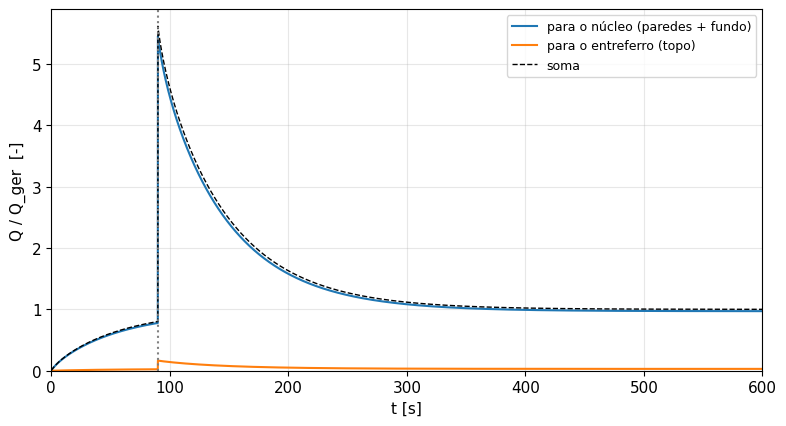

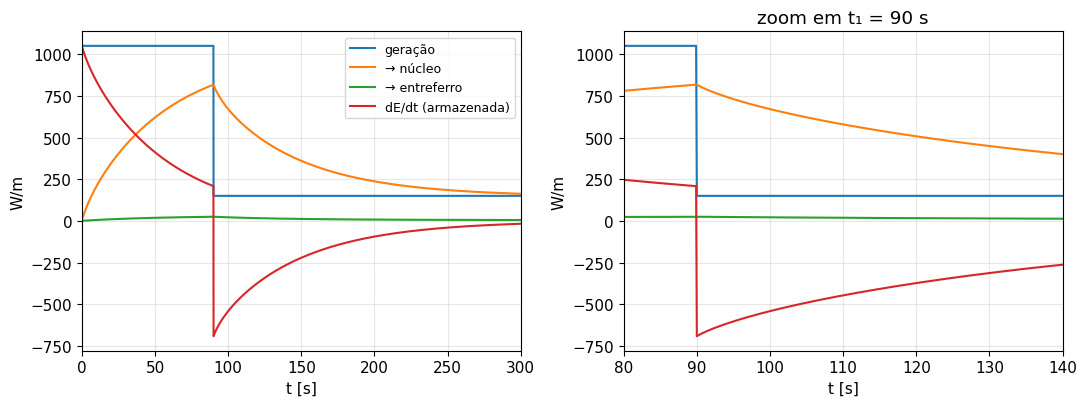

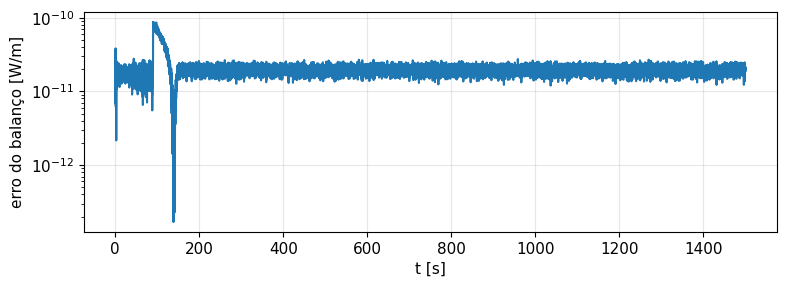

In [20]:
fn, fe = hist_Qnuc / hist_Qger, hist_Qent / hist_Qger
bal = hist_Qger - hist_Qnuc - hist_Qent - hist_dEdt
print(f'Regime permanente: {fn[-1]*100:.1f}% para o núcleo e {fe[-1]*100:.1f}% para o entreferro')
print(f'Em t1- (89,9 s): núcleo = {fn[n1-1]*100:.1f}%, entreferro = {fe[n1-1]*100:.1f}%')
print(f'Erro máximo do balanço de energia: {np.abs(bal).max():.1e} W/m')

fig, ax = plt.subplots(figsize=(8, 4.4))
ax.plot(t, fn, label='para o núcleo (paredes + fundo)')
ax.plot(t, fe, label='para o entreferro (topo)')
ax.plot(t, fn+fe, 'k--', lw=1, label='soma')
ax.axvline(t1, color='gray', ls=':')
ax.set_xlim(0, 600)
ax.set_ylim(bottom=0)
ax.set_xlabel('t [s]')
ax.set_ylabel('Q / Q_ger  [-]')
ax.legend(fontsize=9)
fig.tight_layout()
fig.savefig('figs/fracoes.png', dpi=170)
plt.show()

fig, axs = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, xl in zip(axs, [(0, 300), (80, 140)]):
    ax.plot(t, hist_Qger, label='geração'); ax.plot(t, hist_Qnuc, label='→ núcleo')
    ax.plot(t, hist_Qent, label='→ entreferro'); ax.plot(t, hist_dEdt, label='dE/dt (armazenada)')
    ax.set_xlim(*xl); ax.set_xlabel('t [s]'); ax.set_ylabel('W/m')
axs[0].legend(fontsize=9)
axs[1].set_title('zoom em t₁ = 90 s')
fig.tight_layout()
fig.savefig('figs/taxas.png', dpi=170)
plt.show()

fig, ax = plt.subplots(figsize=(8, 3))
ax.semilogy(t, np.abs(bal)+1e-16)
ax.set_xlabel('t [s]')
ax.set_ylabel('erro do balanço [W/m]')
fig.tight_layout()
plt.show()

## 8. Resultado (e) — temperatura nos pontos A, B, C e D

Em t = 90 s: A = 150.1, B = 117.6, C = 162.6, D = 116.1 °C


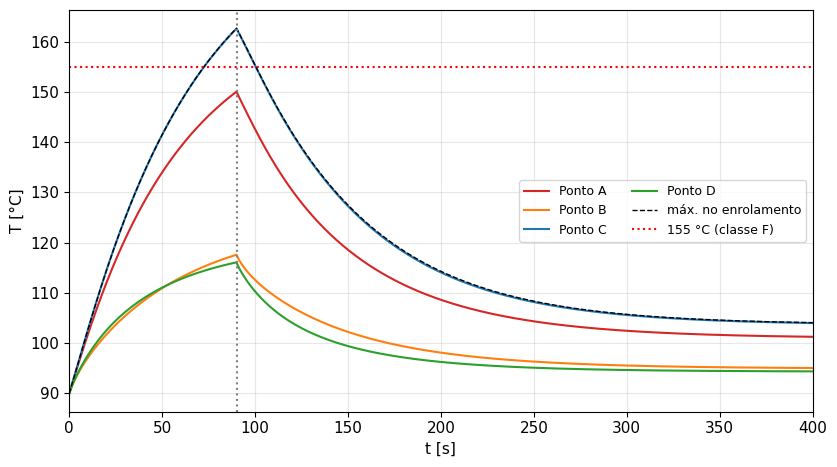

In [21]:
print(f'Em t = 90 s: A = {hist_A[n1]:.1f}, B = {hist_B[n1]:.1f}, C = {hist_C[n1]:.1f}, D = {hist_D[n1]:.1f} °C')
fig, ax = plt.subplots(figsize=(8.5, 4.8))
for nome_ponto, dados_ponto, cor in zip(['A', 'B', 'C', 'D'], [hist_A, hist_B, hist_C, hist_D], ['C3', 'C1', 'C0', 'C2']):
    ax.plot(t, dados_ponto, label=f'Ponto {nome_ponto}', color=cor)
ax.plot(t, hist_Tmax, 'k--', lw=1, label='máx. no enrolamento')
ax.axhline(Tmax_isol, color='r', ls=':', label='155 °C (classe F)')
ax.axvline(t1, color='gray', ls=':')
ax.set_xlim(0, 400)
ax.set_xlabel('t [s]')
ax.set_ylabel('T [°C]')
ax.legend(ncol=2, fontsize=9)
fig.tight_layout()
fig.savefig('figs/pontos.png', dpi=170)
plt.show()

## 9. Campos de temperatura (mapas de cor)

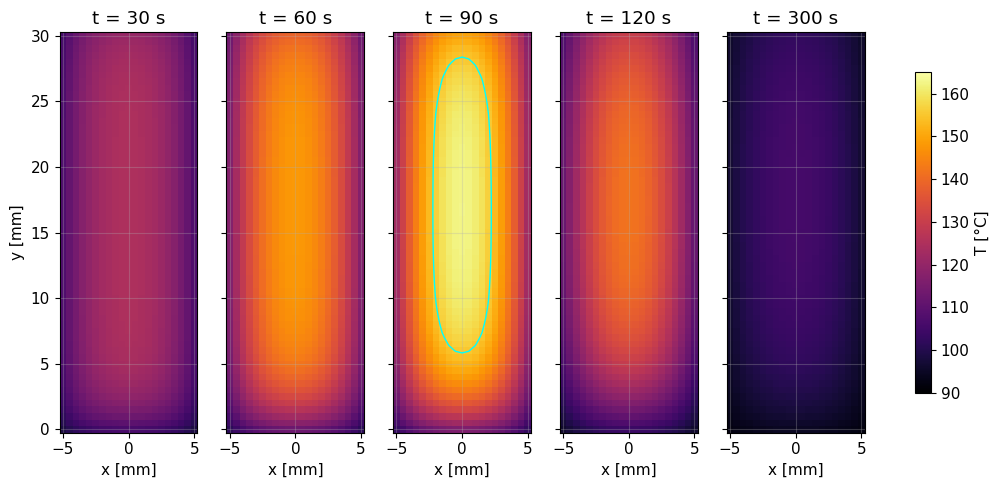

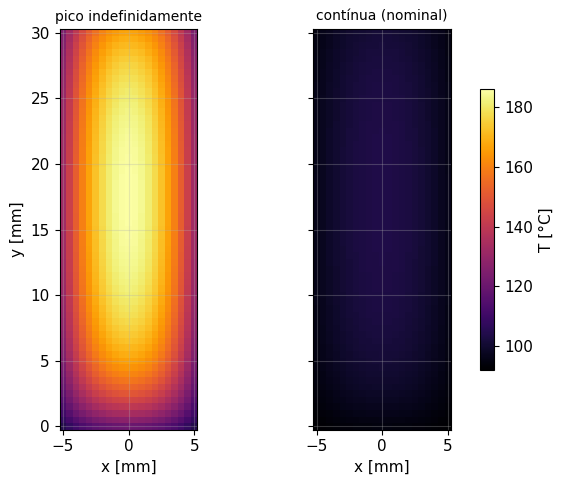

In [22]:
Xf = np.concatenate([-x[::-1][:-1], x])*1e3
espelha = lambda T: np.concatenate([T[:, ::-1][:, :-1], T], axis=1)

fig, axs = plt.subplots(1, 5, figsize=(13, 5.2), sharey=True)
for ax, s in zip(axs, [30, 60, 90, 120, 300]):
    idx_snap = snaps.index(s)    # procura a posição do tempo s na lista snaps
    campo_s = campos_lista[idx_snap]
    im = ax.pcolormesh(Xf, y*1e3, espelha(campo_s), cmap='inferno', vmin=90, vmax=165, shading='auto')
    ax.contour(Xf, y*1e3, espelha(campo_s), levels=[155], colors='cyan', linewidths=1)
    ax.set_title(f't = {s} s'); ax.set_aspect('equal'); ax.set_xlabel('x [mm]')
axs[0].set_ylabel('y [mm]')
fig.colorbar(im, ax=axs, label='T [°C]', shrink=.8)
fig.savefig('figs/campos.png', dpi=170, bbox_inches='tight')
plt.show()


fig, axs = plt.subplots(1, 2, figsize=(7.5, 5.2), sharey=True)
vmin = min(Tss1.min(), Tss2.min())
vmax = max(Tss1.max(), Tss2.max())
for ax, T_, tt in zip(axs, [Tss1, Tss2], ['pico indefinidamente', 'contínua (nominal)']):
    im = ax.pcolormesh(Xf, y*1e3, espelha(T_), cmap='inferno', vmin=vmin, vmax=vmax, shading='auto')
    ax.set_aspect('equal')
    ax.set_title(tt, fontsize=10)
    ax.set_xlabel('x [mm]')
axs[0].set_ylabel('y [mm]')
fig.colorbar(im, ax=axs, shrink=.7, label='T [°C]')
fig.savefig('figs/permanentes.png', dpi=170, bbox_inches='tight')
plt.show()

## 10. GIF da evolução da temperatura
(uns 20s)

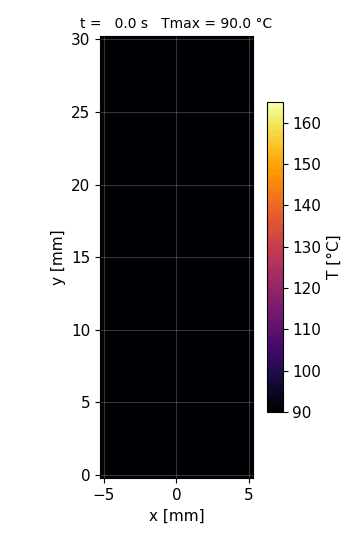

In [23]:
import imageio.v2 as imageio
frames = []
for tt, Tg in zip(gif_tempos, gif_campos):
    if tt > 300: break
    f, ax = plt.subplots(figsize=(3.6, 5.4))
    im = ax.pcolormesh(Xf, y*1e3, espelha(Tg), cmap='inferno', vmin=90, vmax=165, shading='auto')
    ax.set_aspect('equal'); ax.set_title(f't = {tt:5.1f} s   Tmax = {Tg.max():.1f} °C', fontsize=10)
    f.colorbar(im, label='T [°C]', shrink=.7); ax.set_xlabel('x [mm]'); ax.set_ylabel('y [mm]'); f.tight_layout()
    f.canvas.draw(); frames.append(np.asarray(f.canvas.buffer_rgba())[..., :3].copy()); plt.close(f)
imageio.mimsave('figs/aquecimento.gif', frames, duration=0.12, loop=0)
try:
    from IPython.display import Image, display
    display(Image('figs/aquecimento.gif'))
except Exception:
    print('GIF salvo em figs/aquecimento.gif')

## 11. Extras  (convergência de malha e análise de sensibilidade)
Mais lento (a malha de 0,25 mm exige passo de tempo menor).
Mudar `RODAR_EXTRAS` para `True` ou `False` dependendo se quer que rode junto com todo o resto (tá dando uns 40s)

Convergência de malha
Delta [mm]    nós   dt [s]  Tmax(t<=100s)  t1,max [s]  Tmax ss cont.
      1.00    186    0.100         162.65        72.5         103.70
      0.50    671    0.100         162.66        72.4         103.70
      0.25   2541    0.043         162.65        72.5         103.70

Sensibilidade (malha base)
        caso  Tmax(150 s)  t1,max [s]   ss pico  ss cont.
        base        162.7        72.4     185.9     103.7
   h_n = 200        174.0        61.6     225.5     109.4
   h_n = 800        153.5   > 90 (ok)     165.4     100.8
    h_e = 10        162.8        72.3     187.2     103.9
   h_e = 200        162.5        72.6     184.5     103.5
     k = 0,4        179.4        57.5     240.0     111.4
     k = 1,6        148.7   > 90 (ok)     158.6      99.8
  e1 = 3,0e6        152.3   > 90 (ok)     172.2     103.7
  e1 = 4,0e6        173.0        58.0     199.6     103.7


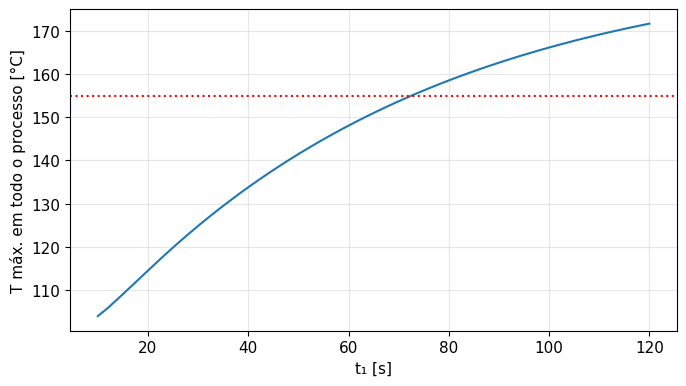

In [24]:
RODAR_EXTRAS = True

if RODAR_EXTRAS:
    print('Convergência de malha')
    print(f'{'Delta [mm]':>10} {'nós':>6} {'dt [s]':>8} {'Tmax(t<=100s)':>14} {'t1,max [s]':>11} {'Tmax ss cont.':>14}')
    for D in (1e-3, 0.5e-3, 0.25e-3):
        nx_m, ny_m, x_m, y_m, V_m, C_m, Hlat_m, Hbot_m, Htop_m = criar_malha(D)
        d, _ = escolhe_dt(D, 0.1)
        res_sim = simula(D, nx_m, ny_m, x_m, y_m, V_m, C_m, Hlat_m, Hbot_m, Htop_m, d, 100.0)
        tmax_sim = res_sim[7] # hist_Tmax é o 8º item retornado (índice 7)
        tm = t1_maximo(D, nx_m, ny_m, d)
        print(f'{D*1e3:10.2f} {nx_m*ny_m:6d} {d:8.3f} {tmax_sim.max():14.2f} {tm[0]:11.1f} {permanente(D, nx_m, ny_m, e2).max():14.2f}')

    print('\nSensibilidade (malha base)')
    print(f'{'caso':>12} {'Tmax(150 s)':>12} {'t1,max [s]':>11} {'ss pico':>9} {'ss cont.':>9}')

    def caso(nome, novo_hn=400.0, novo_he=50.0, novo_k=0.8, novo_e1=3.5e6):
        global hn, he, k, e1, alpha
        hn, he, k, e1 = novo_hn, novo_he, novo_k, novo_e1
        alpha = k / (rho * cp)

        nx_m, ny_m, x_m, y_m, V_m, C_m, Hlat_m, Hbot_m, Htop_m = criar_malha(DELTA)
        d, _ = escolhe_dt(DELTA, 0.1)
        res_sim = simula(DELTA, nx_m, ny_m, x_m, y_m, V_m, C_m, Hlat_m, Hbot_m, Htop_m, d, 150.0)
        tmax_sim = res_sim[7]
        tm = t1_maximo(DELTA, nx_m, ny_m, d)
        print(f'{nome:>12} {tmax_sim.max():12.1f} {(f'{tm[0]:.1f}' if tm else '> 90 (ok)'):>11} '
              f'{permanente(DELTA, nx_m, ny_m, e1).max():9.1f} {permanente(DELTA, nx_m, ny_m, e2).max():9.1f}')

        # Volta pros padrões originais
        hn, he, k, e1 = 400.0, 50.0, 0.8, 3.5e6
        alpha = k / (rho * cp)

    caso('base')
    caso('h_n = 200', novo_hn=200.0); caso('h_n = 800', novo_hn=800.0)
    caso('h_e = 10', novo_he=10.0);   caso('h_e = 200', novo_he=200.0)
    caso('k = 0,4', novo_k=0.4);      caso('k = 1,6', novo_k=1.6)
    caso('e1 = 3,0e6', novo_e1=3.0e6); caso('e1 = 4,0e6', novo_e1=4.0e6)

    t1s = np.arange(10, 121, 2.0)
    pk = [pico_apos(DELTA, nx, ny, dt, float(np.round(x_val/dt)*dt)) for x_val in t1s]
    fig, ax = plt.subplots(figsize=(7, 4)); ax.plot(t1s, pk); ax.axhline(155, color='r', ls=':')
    ax.set_xlabel('t₁ [s]'); ax.set_ylabel('T máx. em todo o processo [°C]'); fig.tight_layout()
    fig.savefig('figs/pico_vs_t1.png', dpi=170); plt.show()